# 02 — Factor returns and specific returns

**Step 4 of the model.** One constrained, cap-weighted cross-sectional regression
per month:

$$r_i(t) = f_{\text{market}}(t) + \sum_p X_{ip}(t-1)\, f_p^{\text{ind}}(t) + \sum_k X_{ik}(t-1)\, f_k^{\text{sty}}(t) + u_i(t)$$

The fitted coefficients are the **factor returns** `f(t)`; the residuals are the
**specific returns** `u(i,t)`. They are the same object seen from two sides and
cannot be computed separately — a specific return is *defined* as what the factor
returns fail to explain.

Reads `ryan_sample_exposures`. Writes `ryan_sample_factor_returns`,
`ryan_sample_specific_returns` and `ryan_sample_regression_diag`. Run top to
bottom.

### Three things here are not a plain `lstsq` call

1. **The design matrix is rank-deficient by construction.** The 11 industry
   dummies sum, row by row, to the market factor's column of ones. `lstsq` returns
   *a* minimum-norm solution, but it is an arbitrary point on a one-dimensional
   family of equally good fits and it drifts month to month for numerical reasons
   alone — which would make `F` garbage. USE4 pins it with the cap-weighted
   constraint $\sum_p \text{CAP}_p f_p^{\text{ind}} = 0$.

2. **Exposures are lagged one month.** `ret_exc` at eom *t* is the return
   *during* month *t*, while `market_equity` at eom *t* is the cap *after* that
   month's move. Since `be_me`, `ni_me`, `ocf_me` and log size all divide by (or
   are) that market equity, a contemporaneous fit hands the regression the very
   return it is meant to explain. Cell 6 measures the damage.

3. **The dependent variable is winsorized** (not standardized — it keeps its
   units), as secondary insurance against extreme returns. Stage 5 measures how
   much of the work each fix actually does; the answer is not the obvious one.

In [1]:
import os
import sys

sys.path.insert(0, os.getcwd())

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
import db
import factor_returns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

# Validated categorical palette: passes the lightness band, chroma floor,
# adjacent-pair CVD separation and the normal-vision floor. The three lower-
# contrast hues are always paired with a direct label, never colour alone.
STYLE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
INK, ACCENT, MUTED = "#2a78d6", "#e34948", "#8a8a83"

print(f"lag exposures         {config.LAG_EXPOSURES}")
print(f"return winsor sigma   {config.WINSOR_RETURN_SIGMA}")
print(f"reading               {config.TBL_EXPOSURES}")

lag exposures         True
return winsor sigma   8.0
reading               ryan_sample_exposures


In [2]:
engine = db.get_engine()
db.check_connection(engine)

✅ Connected to Postgres/TimescaleDB at timescaledb


---
## Stage 1 — Load the exposures

`X(t)` comes straight out of 01. Nothing is recomputed here: if the exposures
need to change, change them there and re-run that notebook, so the stored `X`
and the `f` fitted from it never disagree.

In [3]:
if not db.table_exists(engine, config.TBL_EXPOSURES):
    raise RuntimeError(
        f"{config.TBL_EXPOSURES} is missing — run run_pipeline.ipynb first."
    )

exposures = db.read_table(config.TBL_EXPOSURES, engine)
exposures["eom"] = pd.to_datetime(exposures["eom"])

style_cols = [c for c in exposures.columns if c.startswith("f_")]
dummy_cols = [c for c in exposures.columns if c.startswith("ind_")]
n_factors = 1 + len(dummy_cols) + len(style_cols)

print(f"📂 {len(exposures):,} rows / {exposures['id'].nunique()} securities / "
      f"{exposures['eom'].nunique()} months")
print(f"   {exposures['eom'].min().date()} → {exposures['eom'].max().date()}")
print(f"\nK = {n_factors}: 1 market + {len(dummy_cols)} industries + {len(style_cols)} styles")
print(f"   styles:     {', '.join(c[2:] for c in style_cols)}")
print(f"   industries: {', '.join(dummy_cols)}")
exposures.head()

📂 41,334 rows / 220 securities / 241 months
   2005-12-31 → 2025-12-31

K = 18: 1 market + 11 industries + 6 styles
   styles:     value, size, momentum, profitability, investment, beta
   industries: ind_10, ind_15, ind_20, ind_25, ind_30, ind_35, ind_40, ind_45, ind_50, ind_55, ind_60


,id,eom,gvkey,permno_ccm,ticker,conm,sector_code,sector_name,group_code,group_name,ret_exc,market_equity,f_value,f_size,f_momentum,f_profitability,f_investment,f_beta,ind_10,ind_15,ind_20,ind_25,ind_30,ind_35,ind_40,ind_45,ind_50,ind_55,ind_60
0,10200.0,2005-12-31,012181,10200.0,RGEN,REPLIGEN CORP,35,Health Care,3520,"Pharmaceuticals, Biotechnology & Life Sciences",0.348191,120.45600,-0.773902,-2.561640,-0.329743,-0.518963,-0.299847,1.177874,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
1,10200.0,2006-01-31,012181,10200.0,RGEN,REPLIGEN CORP,35,Health Care,3520,"Pharmaceuticals, Biotechnology & Life Sciences",0.184012,143.04150,-0.937186,-2.497277,1.759903,-0.013922,-0.063228,1.020345,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,10200.0,2006-02-28,012181,10200.0,RGEN,REPLIGEN CORP,35,Health Care,3520,"Pharmaceuticals, Biotechnology & Life Sciences",-0.066480,134.03400,-0.924740,-2.517222,2.225799,-0.019008,-0.064905,0.848246,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,10200.0,2006-03-31,012181,10200.0,RGEN,REPLIGEN CORP,35,Health Care,3520,"Pharmaceuticals, Biotechnology & Life Sciences",-0.172181,112.39860,-0.802766,-2.639770,2.211244,-0.014979,-0.064406,0.604643,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4,10200.0,2006-04-30,012181,10200.0,RGEN,REPLIGEN CORP,35,Health Care,3520,"Pharmaceuticals, Biotechnology & Life Sciences",-0.060316,106.01922,-0.819064,-2.676477,2.191932,0.072899,0.301714,0.963343,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


---
## Stage 2 — The timing problem, measured

Before fitting anything, confirm that the lag is necessary rather than
cosmetic. The test: correlate each exposure with the **same month's** return,
cross-sectionally, then do it again with the exposure lagged one month.

If the panel were properly aligned these two columns would look similar. They do
not. `be_me` uses market equity at eom *t*, so a stock that fell during month *t*
mechanically gets a higher book-to-market — and the regression reads that as
"value stocks underperformed."

In [4]:
# Mean cross-sectional correlation of two columns, averaged over months.
# Columns are selected before .apply so the grouping key is not passed into the
# lambda -- that is what pandas 2.2 deprecated, and selecting explicitly avoids
# the `include_groups` argument, which does not exist before 2.2.
def xs_corr(a, b, groups, min_n=10):
    d = pd.DataFrame({"a": a, "b": b, "g": groups}).dropna()
    per = d.groupby("g")[["a", "b"]].apply(
        lambda x: x["a"].corr(x["b"]) if len(x) > min_n else np.nan
    )
    return per.mean()


ret = pd.to_numeric(exposures[config.RETURN_COL], errors="coerce")
lagged = exposures.sort_values(["id", "eom"]).groupby("id")[style_cols].shift(1)

timing = pd.DataFrame({
    "contemporaneous": [xs_corr(exposures[c], ret, exposures["eom"]) for c in style_cols],
    "lagged 1 month": [xs_corr(lagged[c], ret, exposures["eom"]) for c in style_cols],
}, index=[c[2:] for c in style_cols])
timing["shift"] = timing["lagged 1 month"] - timing["contemporaneous"]
display(timing.round(3))

print("corr(z_be_me, same-month return) is the mechanical channel:")
print("  book/market rises exactly when price falls, within the same month.")
print(f"\n{'⚠️ ' if timing['contemporaneous'].abs().max() > 0.03 else '✅'} "
      f"largest contemporaneous |corr| = {timing['contemporaneous'].abs().max():.3f}, "
      f"lagged = {timing['lagged 1 month'].abs().max():.3f}")

,contemporaneous,lagged 1 month,shift
value,-0.116,0.017,0.133
size,0.045,-0.005,-0.050
momentum,0.018,0.023,0.005
profitability,0.020,0.019,-0.001
investment,0.013,0.010,-0.003
beta,-0.002,-0.003,-0.001


corr(z_be_me, same-month return) is the mechanical channel:
  book/market rises exactly when price falls, within the same month.

⚠️  largest contemporaneous |corr| = 0.116, lagged = 0.023


---
## Stage 3 — Fit every cross-section

`run_panel` does the lag, the winsorization and the constrained WLS. The
constraint is imposed by **substitution** — writing $f = U\theta$ for a
$K \times (K-1)$ basis $U$ that spans the constrained subspace — so it holds to
machine precision rather than approximately. A penalty would only satisfy it
approximately; dropping a column would silently re-baseline every industry
against the dropped one.

Regression weights are $\sqrt{\text{cap}}$. That is also what handles
cross-sectional heteroskedasticity, which is why Newey-West in 03 and 04 is
purely about serial correlation.

In [5]:
F, U, diag, reg_panel = factor_returns.run_panel(exposures, style_cols, dummy_cols)

style_names = [c[2:] for c in style_cols]
core = [factor_returns.MARKET_FACTOR] + style_names
F.head()

⏮  exposures lagged one month: 41,334 → 41,098 rows (each security's first month has no prior exposure)
✂️  dependent variable winsorized at 8.0 robust sigma: 214 of 41,098 observations clipped (0.521%)
📐 fitted 240 cross-sections, 18 factors (11 industries + 6 styles + market)
   median R² = 0.274, median assets = 168, median residual df = 151


,market,ind_10,ind_15,ind_20,ind_25,ind_30,ind_35,ind_40,ind_45,ind_50,ind_55,ind_60,value,size,momentum,profitability,investment,beta
eom,,,,,,,,,,,,,,,,,,
2006-01-31,0.037738,0.038600,0.029385,0.048668,-0.020760,-0.010927,-0.024749,-0.027656,0.044981,-0.014492,-0.038964,-0.016225,0.015869,-0.013086,0.029082,0.001057,-0.008692,0.033603
2006-02-28,-0.026430,-0.075032,-0.021750,0.059457,0.022674,0.023451,0.007801,0.031073,0.046031,0.030849,0.051011,0.043871,0.000301,-0.002855,-0.003845,0.020046,0.003890,0.013121
2006-03-31,0.006473,0.033847,0.013518,-0.015343,0.000881,0.020259,-0.046508,0.002429,0.071108,0.020273,-0.060702,-0.015048,-0.003770,-0.015948,0.010440,-0.007976,0.001210,0.015432
2006-04-30,0.019964,0.024396,0.049936,0.021825,0.000296,-0.015447,-0.066055,-0.006240,-0.073948,0.039054,-0.030486,-0.003948,0.014010,-0.002868,0.029565,-0.000338,-0.002931,0.009228
2006-05-31,-0.019830,0.001359,-0.021728,-0.018296,-0.002044,0.018122,-0.042435,0.014444,-0.019268,0.046280,0.024725,-0.000968,0.012337,0.008646,-0.009412,0.013877,-0.001855,-0.006397


### Verify the fit before believing any of it

Five properties the rest of the model depends on. The constraint check is the
important one — it is the whole reason this is not a one-line `lstsq`.

In [6]:
scale = (diag["constraint_residual"].abs().max())
checks = {
    "every cross-section is full rank": bool(diag["full_rank"].all()),
    "cap-weighted industry constraint holds": scale < 1e-8,
    "no month lost to too-few-assets": len(F) == exposures["eom"].nunique() - 1,
    "no empty industry in any month": int(diag["n_empty_industries"].sum()) == 0,
    "R² is in a sane band": bool((diag["r2"] > 0).all() and (diag["r2"] < 0.95).all()),
    "every factor estimated in every month": bool(F.notna().all().all()),
}
for name, ok in checks.items():
    print(f"{'✅' if ok else '❌'} {name}")

print(f"\nmax |constraint residual|   {scale:.2e}")
print(f"design condition number     median {diag['cond'].median():.1f}, max {diag['cond'].max():.1f}")
print(f"assets per cross-section    median {diag['n_assets'].median():.0f}, "
      f"min {diag['n_assets'].min():.0f}")
print(f"residual df                 median {diag['resid_df'].median():.0f}, "
      f"min {diag['resid_df'].min():.0f}")
display(diag[["n_assets", "resid_df", "r2", "cond", "exposures_filled"]].describe().round(3))

✅ every cross-section is full rank
✅ cap-weighted industry constraint holds
✅ no month lost to too-few-assets
✅ no empty industry in any month
✅ R² is in a sane band
✅ every factor estimated in every month

max |constraint residual|   2.08e-11
design condition number     median 8.6, max 12.7
assets per cross-section    median 168, min 117
residual df                 median 151, min 100


,n_assets,resid_df,r2,cond,exposures_filled
count,240.000,240.000,240.000,240.000,240.000
mean,171.121,154.121,0.295,9.032,18.204
std,34.541,34.541,0.115,1.337,8.199
min,117.000,100.000,0.083,7.093,4.000
25%,137.750,120.750,0.211,8.183,15.000
50%,168.000,151.000,0.274,8.581,18.000
75%,211.250,194.250,0.371,9.756,21.000
max,220.000,203.000,0.626,12.731,50.000


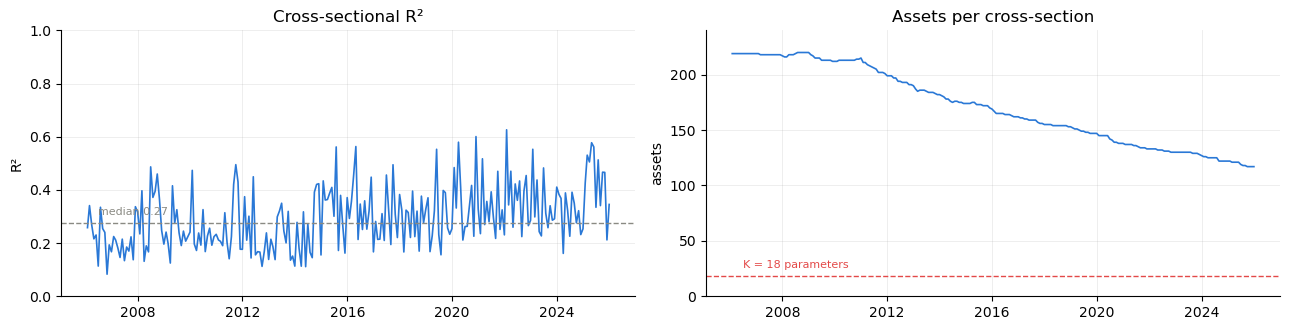

In [7]:
# Fit quality through time. Falling asset counts are expected and wanted: this is
# a fixed 2005 cohort, so the decline IS the delistings we deliberately kept.
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))

ax[0].plot(diag["eom"], diag["r2"], color=INK, lw=1.2)
ax[0].axhline(diag["r2"].median(), color=MUTED, ls="--", lw=1)
ax[0].annotate(f"median {diag['r2'].median():.2f}", (diag["eom"].iloc[5], diag["r2"].median()),
               textcoords="offset points", xytext=(0, 6), color=MUTED, fontsize=8)
ax[0].set(title="Cross-sectional R²", ylabel="R²", ylim=(0, 1))

ax[1].plot(diag["eom"], diag["n_assets"], color=INK, lw=1.2)
ax[1].axhline(n_factors, color=ACCENT, ls="--", lw=1)
ax[1].annotate(f"K = {n_factors} parameters", (diag["eom"].iloc[5], n_factors),
               textcoords="offset points", xytext=(0, 6), color=ACCENT, fontsize=8)
ax[1].set(title="Assets per cross-section", ylabel="assets", ylim=(0, 240))

for a in ax:
    a.grid(alpha=.25, lw=.6)
    a.set_axisbelow(True)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

---
## Stage 4 — The factor returns

Annualized from monthly: mean × 12, volatility × √12. The `t` column is the
simple time-series t-statistic on the mean, which is a fair description of the
*sample* but is not a claim about out-of-sample premia — the cohort filter in 01
(`MIN_RETURN_MONTHS = 60`) excludes firms that delisted 2006–2010.

In [8]:
def annualize(fr):
    n = fr.notna().sum()
    return pd.DataFrame({
        "mean_ann_%": fr.mean() * 12 * 100,
        "vol_ann_%": fr.std() * np.sqrt(12) * 100,
        "t": fr.mean() / (fr.std() / np.sqrt(n)),
        "n": n,
    })


summary = annualize(F)
summary["kind"] = np.where(summary.index == factor_returns.MARKET_FACTOR, "market",
                    np.where(summary.index.str.startswith("ind_"), "industry", "style"))
display(summary.round(2))

print("Sanity anchors — these are the numbers that say the model is calibrated:")
print(f"  market factor      {summary.loc['market', 'mean_ann_%']:.1f}% / yr at "
      f"{summary.loc['market', 'vol_ann_%']:.1f}% vol   (a US equity market)")
sty = summary[summary["kind"] == "style"]
print(f"  style vols         {sty['vol_ann_%'].min():.1f}–{sty['vol_ann_%'].max():.1f}% / yr"
      f"   (USE4 styles run ~2–6%)")
ind = summary[summary["kind"] == "industry"]
print(f"  industry vols      {ind['vol_ann_%'].min():.1f}–{ind['vol_ann_%'].max():.1f}% / yr")

,mean_ann_%,vol_ann_%,t,n,kind
market,7.87,15.38,2.29,240,market
ind_10,-2.24,16.02,-0.62,240,industry
ind_15,5.10,14.72,1.55,240,industry
ind_20,6.87,12.78,2.41,240,industry
ind_25,-0.26,13.49,-0.09,240,industry
ind_30,2.92,8.44,1.55,240,industry
ind_35,0.39,11.69,0.15,240,industry
ind_40,-0.46,10.91,-0.19,240,industry
ind_45,6.85,17.67,1.73,240,industry
ind_50,-0.92,12.43,-0.33,240,industry


Sanity anchors — these are the numbers that say the model is calibrated:
  market factor      7.9% / yr at 15.4% vol   (a US equity market)
  style vols         4.2–7.9% / yr   (USE4 styles run ~2–6%)
  industry vols      8.4–17.7% / yr


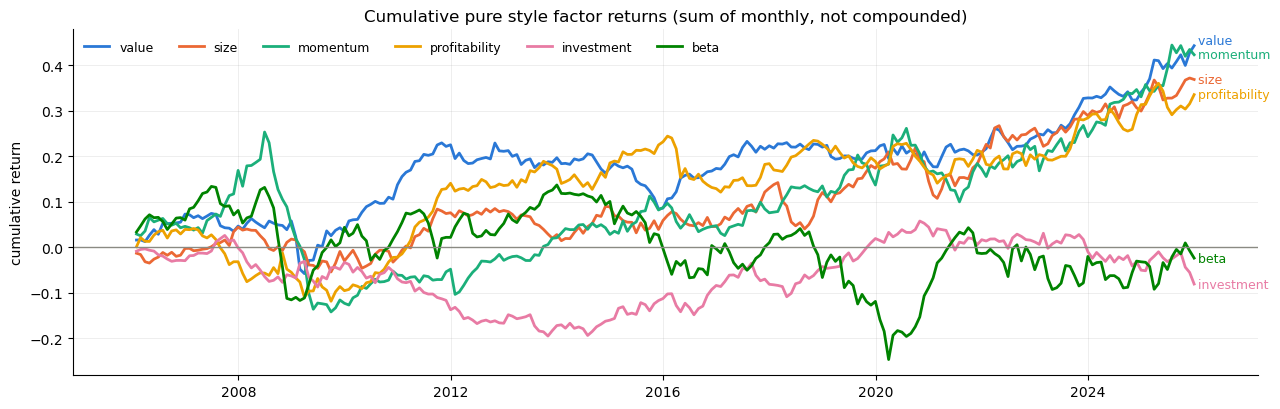

In [9]:
# Cumulative style factor returns. Direct-labelled at the right edge as well as
# legended, so identity never rests on colour alone.
cum = F[style_names].cumsum()

fig, ax = plt.subplots(figsize=(13, 4.2))
for name, color in zip(style_names, STYLE_COLORS):
    ax.plot(cum.index, cum[name], color=color, lw=2, label=name)

# Direct labels, nudged apart where two series finish close together. Without
# this "beta" and "investment" land on top of each other and the direct label --
# the thing carrying identity for the lower-contrast hues -- stops being legible.
ends = cum.iloc[-1].sort_values()
min_gap = (cum.values.max() - cum.values.min()) * 0.045
placed = {}
last = -np.inf
for name in ends.index:
    y = max(ends[name], last + min_gap)
    placed[name] = y
    last = y

for name, color in zip(style_names, STYLE_COLORS):
    ax.annotate(f" {name}", (cum.index[-1], placed[name]), color=color,
                fontsize=9, va="center", fontweight="medium")

ax.axhline(0, color=MUTED, lw=1)
ax.set(title="Cumulative pure style factor returns (sum of monthly, not compounded)",
       ylabel="cumulative return")
ax.legend(ncol=6, frameon=False, loc="upper left", fontsize=9)
ax.grid(alpha=.25, lw=.6)
ax.set_axisbelow(True)
ax.margins(x=.06)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

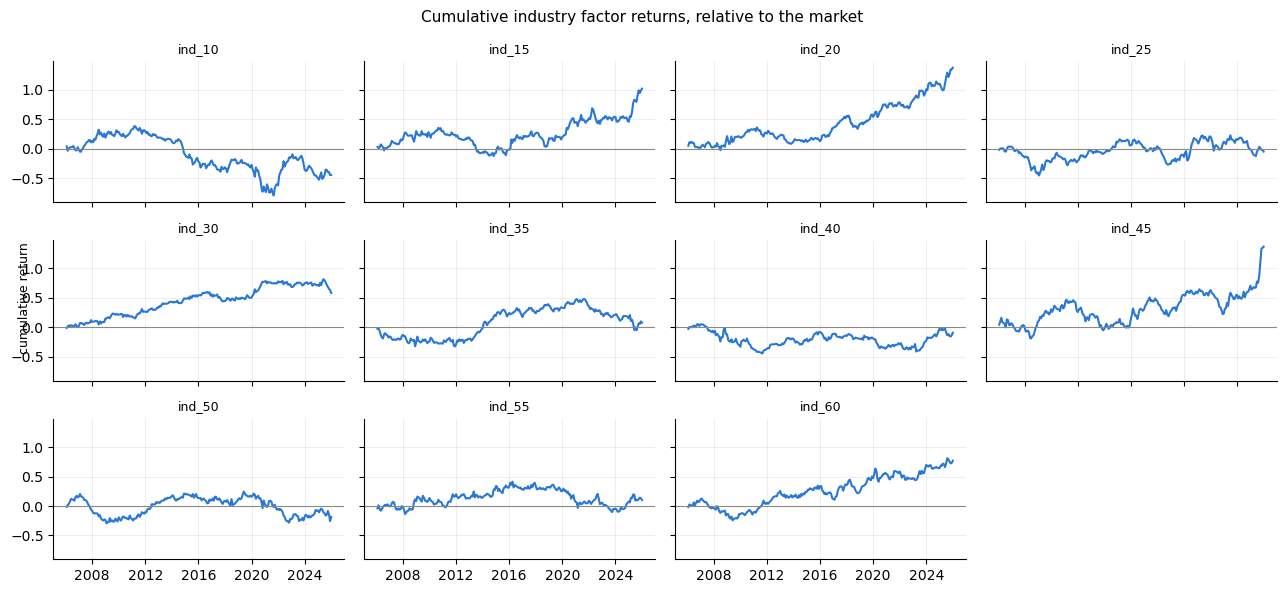

In [10]:
# Industries as small multiples rather than 11 lines on one axis -- past about
# eight series a single panel stops being readable whatever the palette.
ind_cum = F[dummy_cols].cumsum()
fig, axes = plt.subplots(3, 4, figsize=(13, 6), sharex=True, sharey=True)
lo, hi = ind_cum.min().min(), ind_cum.max().max()

for ax, col in zip(axes.ravel(), dummy_cols):
    ax.plot(ind_cum.index, ind_cum[col], color=INK, lw=1.5)
    ax.axhline(0, color=MUTED, lw=.8)
    ax.set_title(col, fontsize=9)
    ax.grid(alpha=.25, lw=.6)
    ax.set_axisbelow(True)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
for ax in axes.ravel()[len(dummy_cols):]:
    ax.set_visible(False)

fig.suptitle("Cumulative industry factor returns, relative to the market", fontsize=11)
fig.supylabel("cumulative return", fontsize=9)
plt.tight_layout()
plt.show()

---
## Stage 5 — A first look at `F`

This is not the covariance the model will ship — 03 adds Newey-West, exponential
decay, the Volatility Regime Adjustment and the eigenfactor adjustment, all on a
rolling window. This is the raw sample covariance of the fitted factor returns,
and its job here is to show whether the regression produced something a
covariance estimator can work with at all.

What to look for: style correlations should be **small**. These are *pure* factor
returns — each one is already purged of the others and of industry — so they
should not look like long-short strategy returns, which are much more correlated.
A large off-diagonal here means the regression is trading one factor off against
another, not that the factors are economically related.

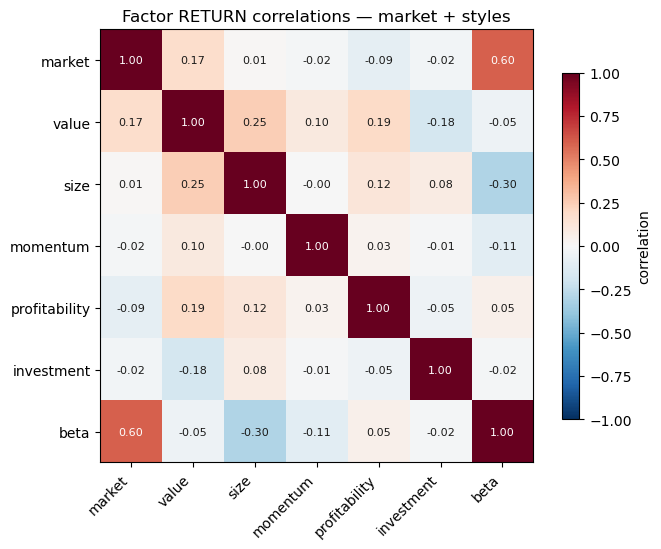

largest off-diagonal |correlation| = 0.596  (market ↔ beta)

market ↔ beta is expected and correct: Beta is deliberately NOT
orthogonalized against the market in USE4, so the beta factor return
carries market direction by design.


In [11]:
corr = F[core].corr()

fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(core)), core, rotation=45, ha="right")
ax.set_yticks(range(len(core)), core)
# Every cell carries its number, so the reading never depends on the colour.
for i in range(len(core)):
    for j in range(len(core)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > .55 else "#1a1a19")
plt.colorbar(im, shrink=.8, label="correlation")
ax.set_title("Factor RETURN correlations — market + styles")
plt.tight_layout()
plt.show()

off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
worst = off.stack().idxmax()
print(f"largest off-diagonal |correlation| = {off.max().max():.3f}  ({worst[0]} ↔ {worst[1]})")
print("\nmarket ↔ beta is expected and correct: Beta is deliberately NOT")
print("orthogonalized against the market in USE4, so the beta factor return")
print("carries market direction by design.")

T = 240 months, K = 18 factors  →  T/K = 13.3
eigenvalues   min 9.125e-05   max 4.076e-03   condition 44.7
✅ positive definite (0 non-positive eigenvalues)

⚠️  T/K here is the FULL-SAMPLE ratio. On the 60-month rolling window 03
    will use, T/K ≈ 3.3 — where eigenvalue bias is severe and the
    eigenfactor adjustment stops being a refinement.


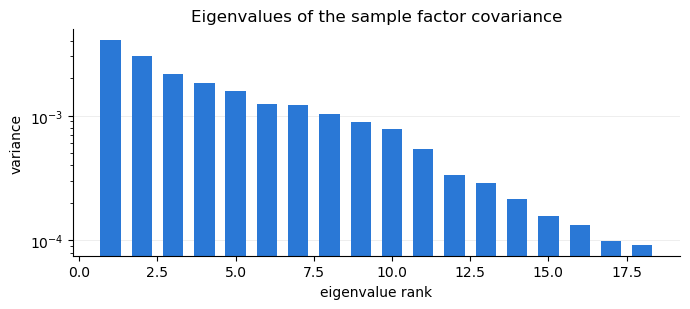

In [12]:
# Conditioning of the full K x K sample covariance. 03 replaces this, but if the
# raw version is already indefinite there is a problem upstream of the estimator.
cov = F.cov()
ev = np.linalg.eigvalsh(cov.values)

print(f"T = {len(F)} months, K = {cov.shape[0]} factors  →  T/K = {len(F) / cov.shape[0]:.1f}")
print(f"eigenvalues   min {ev.min():.3e}   max {ev.max():.3e}   condition {ev.max() / ev.min():.1f}")
print(f"{'✅' if (ev > 0).all() else '❌'} positive definite ({int((ev <= 0).sum())} non-positive eigenvalues)")
print("\n⚠️  T/K here is the FULL-SAMPLE ratio. On the 60-month rolling window 03")
print("    will use, T/K ≈ 3.3 — where eigenvalue bias is severe and the")
print("    eigenfactor adjustment stops being a refinement.")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(1, len(ev) + 1), ev[::-1], color=INK, width=.65)
ax.set(title="Eigenvalues of the sample factor covariance", xlabel="eigenvalue rank",
       ylabel="variance", yscale="log")
ax.grid(alpha=.25, lw=.6, axis="y")
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

### Which fix is doing the work

Both knobs off, both on, and each alone. Worth running rather than assuming,
because the intuitive attribution is **wrong**: the outlier looks like the
disease and is actually a symptom.

SHARPLINK INC returned +2225% in 2025-05. Its market cap went from **\$2.0M to
\$4,575M during that same month** — so a contemporaneous fit weights it by the
*post-spike* cap and hands one observation the entire covariance matrix. Lagging
takes the weight from the pre-spike \$2.0M, and the leverage disappears without
any trimming at all.

Watch the second row especially. Winsorizing *without* fixing the timing makes
the look-ahead look **more** convincing, not less — it strips the noise while
leaving the bias intact, so the spurious value premium's t-statistic goes from
−4.7 to −12.4. Fixing the symptom would have produced a confidently wrong model.

In [13]:
grid = []
for lag in (False, True):
    for win in (None, config.WINSOR_RETURN_SIGMA):
        Fg, _, _, _ = factor_returns.run_panel(
            exposures, style_cols, dummy_cols,
            lag_exposures=lag, winsor_return_sigma=win, verbose=False,
        )
        cg = Fg[style_names].corr()
        off_diag = ~np.eye(len(style_names), dtype=bool)
        grid.append({
            "lag": "on" if lag else "off",
            "winsor": "off" if win is None else f"{win:g}σ",
            "corr(value,momentum)": cg.loc["value", "momentum"],
            "max |style corr|": cg.where(off_diag).abs().max().max(),
            "max style vol %/yr": Fg[style_names].std().max() * np.sqrt(12) * 100,
            "value %/yr": Fg["value"].mean() * 12 * 100,
            "value t": Fg["value"].mean() / (Fg["value"].std() / np.sqrt(len(Fg))),
            "market vol %/yr": Fg["market"].std() * np.sqrt(12) * 100,
        })

display(pd.DataFrame(grid).round(3))

print("The lag is the primary fix — it corrects the SIGN of the value premium")
print("(−18.1%/yr → +2.3%/yr) and defuses the outlier as a side effect.")
print("Winsorization is a modest refinement once the timing is right.")
print("\nThe cap that causes it all:")
spike = exposures[(exposures["id"] == 84819.0)
                  & exposures["eom"].isin(pd.to_datetime(["2025-04-30", "2025-05-31"]))]
display(spike[["eom", "conm", config.RETURN_COL, config.CAP_COL]])

,lag,winsor,"corr(value,momentum)",max |style corr|,max style vol %/yr,value %/yr,value t,market vol %/yr
0,off,off,0.942,0.942,21.911,-21.256,-4.478,15.011
1,off,8σ,0.374,0.374,12.117,-16.487,-13.830,14.959
2,on,off,0.123,0.313,7.946,2.087,1.926,15.380
3,on,8σ,0.101,0.301,7.867,2.214,2.122,15.377


The lag is the primary fix — it corrects the SIGN of the value premium
(−18.1%/yr → +2.3%/yr) and defuses the outlier as a side effect.
Winsorization is a modest refinement once the timing is right.

The cap that causes it all:


,eom,conm,ret_exc,market_equity
28642,2025-04-30,SHARPLINK INC,-0.058862,2.038933
28643,2025-05-31,SHARPLINK INC,22.247113,4575.308400


---
## Stage 6 — The specific returns

`u(i,t)` is the input to `Δ` in 04. Two properties matter now.

**Orthogonality.** The residuals are weight-orthogonal to every column of the
design by construction, so a non-zero value here would mean the solver is wrong.

**Dispersion through time.** The cross-sectional spread of `u` is the raw
material for specific risk, and it is strongly time-varying — which is exactly
why 04 needs exponential decay and a volatility regime adjustment rather than a
flat historical mean.

specific returns: 41,069 rows, 220 securities
cross-sectional σ(u): median 0.1055/month (36.6%/yr annualized)
   range 24.5% – 81.8%/yr   — a 3.3× swing

✅ max |u| = 1.099


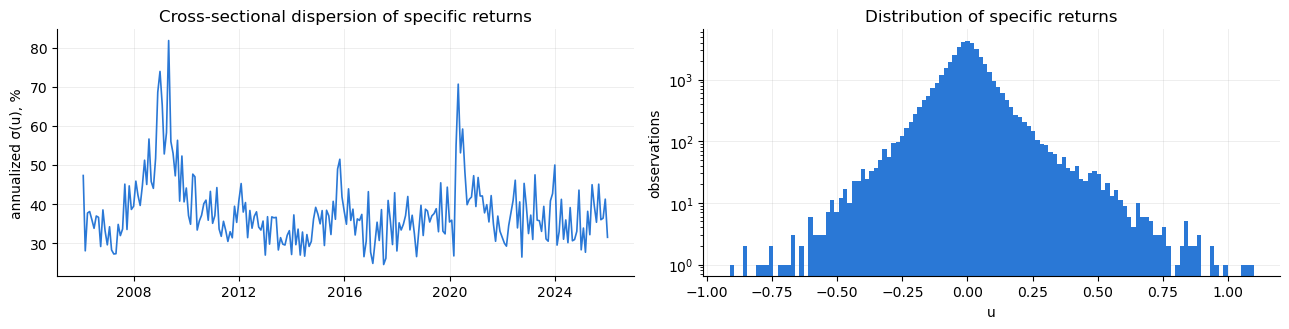

In [14]:
u_stats = U.groupby("eom")["specific_return"].agg(["count", "mean", "std"])
u_stats["ann_vol_%"] = u_stats["std"] * np.sqrt(12) * 100

print(f"specific returns: {len(U):,} rows, {U['id'].nunique()} securities")
print(f"cross-sectional σ(u): median {u_stats['std'].median():.4f}/month "
      f"({u_stats['ann_vol_%'].median():.1f}%/yr annualized)")
print(f"   range {u_stats['ann_vol_%'].min():.1f}% – {u_stats['ann_vol_%'].max():.1f}%/yr"
      f"   — a {u_stats['ann_vol_%'].max() / u_stats['ann_vol_%'].min():.1f}× swing")
print(f"\n{'✅' if U['specific_return'].abs().max() < 2 else '⚠️ '} "
      f"max |u| = {U['specific_return'].abs().max():.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(u_stats.index, u_stats["ann_vol_%"], color=INK, lw=1.2)
ax[0].set(title="Cross-sectional dispersion of specific returns",
          ylabel="annualized σ(u), %")
ax[1].hist(U["specific_return"], bins=120, color=INK)
ax[1].set(title="Distribution of specific returns", xlabel="u", ylabel="observations",
          yscale="log")
for a in ax:
    a.grid(alpha=.25, lw=.6)
    a.set_axisbelow(True)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

In [15]:
# Serial correlation in u is what Newey-West exists to handle in 04. Measure it
# now so that choice is evidence-based rather than inherited.
ac = (U.sort_values(["id", "eom"])
        .groupby("id")["specific_return"]
        .apply(lambda s: s.autocorr(lag=1) if s.notna().sum() > 24 else np.nan)
        .dropna())
print(f"lag-1 autocorrelation of u, across {len(ac)} securities:")
print(f"   mean {ac.mean():+.3f}   median {ac.median():+.3f}   "
      f"[p10 {ac.quantile(.1):+.3f}, p90 {ac.quantile(.9):+.3f}]")
print(f"   share negative: {(ac < 0).mean():.0%}")
print(f"\nrule-of-thumb Newey-West lag for T = {len(F)}: "
      f"L ≈ 4(T/100)^(2/9) = {4 * (len(F) / 100) ** (2 / 9):.1f}")

lag-1 autocorrelation of u, across 220 securities:
   mean -0.047   median -0.042   [p10 -0.171, p90 +0.077]
   share negative: 68%

rule-of-thumb Newey-West lag for T = 240: L ≈ 4(T/100)^(2/9) = 4.9


---
## Stage 7 — Write the artifacts

Three tables. Factor returns go out **long** — `(eom, factor, factor_return)` —
because 03 needs to pivot them by forecast date and a long table survives adding
or removing a factor without a schema change. Specific returns are `(id, eom)`,
the grain `Δ` is estimated on.

In [16]:
f_long = factor_returns.to_long(F)
db.write_table(f_long, config.TBL_FACTOR_RETURNS, engine, unique_on=["eom", "factor"])

u_out = U[["id", "eom", "specific_return", "reg_weight"]].copy()
db.write_table(u_out, config.TBL_SPECIFIC_RETURNS, engine, unique_on=["id", "eom"])

db.write_table(diag, config.TBL_REGRESSION_DIAG, engine, unique_on=["eom"])

# The regression panel: every row the fit actually saw, carrying BOTH dates.
# Stored because ryan_sample_exposures is keyed (id, eom) meaning "the exposures
# observed at eom" — true, but a trap for anything that reads it. Regressing ITS
# ret_exc on ITS OWN f_* columns is the contemporaneous fit, and it reports a
# value factor return of −18.1%/yr at t = −4.7 with every diagnostic looking
# healthy. Here the alignment is legible in the data instead of implicit in code.
panel_cols = (["id", "eom", "exposure_eom", config.RETURN_COL, "ret_exc_raw",
               config.CAP_COL] + style_cols + dummy_cols)
db.write_table(reg_panel[[c for c in panel_cols if c in reg_panel.columns]],
               config.TBL_REGRESSION_PANEL, engine, unique_on=["id", "eom"])

display(f_long.head())
print(f"\nfactor returns   {len(f_long):,} rows  ({F.shape[1]} factors × {len(F)} months)")
print(f"specific returns {len(u_out):,} rows")
print(f"diagnostics      {len(diag):,} rows")
print(f"regression panel {len(reg_panel):,} rows")

gap = (reg_panel["eom"].dt.to_period("M")
       - reg_panel["exposure_eom"].dt.to_period("M")).apply(lambda x: x.n)
print(f"{'✅' if (gap == 1).all() else '❌'} exposure_eom is exactly one month "
      f"before eom in every row of the stored panel")

✅ Wrote 4,320 rows to ryan_sample_factor_returns (unique on ['eom', 'factor'])
✅ Wrote 41,069 rows to ryan_sample_specific_returns (unique on ['id', 'eom'])
✅ Wrote 240 rows to ryan_sample_regression_diag (unique on ['eom'])
✅ Wrote 41,098 rows to ryan_sample_regression_panel (unique on ['id', 'eom'])


,eom,factor,factor_return,factor_type
0,2006-01-31,beta,0.033603,style
1,2006-01-31,ind_10,0.038600,industry
2,2006-01-31,ind_15,0.029385,industry
3,2006-01-31,ind_20,0.048668,industry
4,2006-01-31,ind_25,-0.020760,industry



factor returns   4,320 rows  (18 factors × 240 months)
specific returns 41,069 rows
diagnostics      240 rows
regression panel 41,098 rows
✅ exposure_eom is exactly one month before eom in every row of the stored panel


---
## What 03 does next

`F(t)` — a rolling `K×K` covariance of these factor returns, on a parameterized
window (set the window to "everything" to recover a single full-sample `F` as a
diagnostic). Newey-West with Bartlett weights for serial correlation, exponential
decay for time-varying level, the Volatility Regime Adjustment, then the
eigenfactor adjustment.

On a 60-month window `T/K ≈ 3.3`, so eigenvalue bias is severe and the
eigenfactor adjustment is a correctness requirement, not a refinement — a
min-variance optimizer specifically seeks out the eigenvector where `F̂` is most
wrong, and in-sample that is invisible by construction.

Shared Newey-West and decay helpers belong in a new `riskmath.py`, since 04 needs
the same ones for `Δ`.

### Two open decisions this notebook surfaced

1. **`f_value` is a value/quality blend, not value.** `be_me` correlates −0.33
   with momentum exposure; `ni_me` correlates **+0.14**, because its numerator's
   cross-sectional dispersion swamps the price channel. Blended, value ↔ momentum
   exposure is only −0.09 and value ↔ profitability is +0.19. Dropping
   `STYLE_DESCRIPTORS["value"]` to `["be_me"]` — which is what USE4 does — would
   restore a clean value factor. It changes every number downstream.

2. **The cohort filter biases specific risk low.** `MIN_RETURN_MONTHS = 60`
   excludes firms that delisted 2006–2010. Fine for building the machinery,
   not fine for any out-of-sample claim.